## Semiconductor Lab B7 - Task 5

Measure the mode spectrum at an operating current above the threshold. Determine the
effective refractive index of the active material from the mode separation and the
length of the resonator, which has been determined by means of a light microscope
before. The dispersion shall be neglected: $(d\bar{n}/d\lambda) \to 0$.

In [40]:
%matplotlib inline

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

from b7.python.config import DATA_DIR, PLOTS_DIR, SINGLE_COLUMN
from b7.python.helper import read_spectrum

In [41]:
data_dir: Path = DATA_DIR / "task_5"
export_dir: Path = PLOTS_DIR

### Import Data

In [42]:
df_19mA: pd.DataFrame = read_spectrum(data_dir / "19mA.txt")

### Enrich Data

In [47]:
peaks, _ = find_peaks(df_19mA["signal"], prominence=0.002)
lambda_peaks: np.ndarray = df_19mA["lambda_nm"].to_numpy()[peaks]
signal_peaks: np.ndarray = df_19mA["signal"].to_numpy()[peaks]

d_lambda: np.ndarray = np.diff(lambda_peaks)
d_lambda_mean: float = d_lambda.mean()
d_lambda_sem: float = d_lambda.std(ddof=1) / np.sqrt(len(d_lambda))
lambda_mean: float = lambda_peaks.mean()

pprint({
    "n_peaks": len(lambda_peaks),
    "lambda_peaks_nm": [float(f) for f in lambda_peaks],
    "d_lambda_mean_nm": d_lambda_mean,
    "d_lambda_sem_nm": d_lambda_sem,
    "lambda_mean_nm": lambda_mean,
})

{'d_lambda_mean_nm': np.float64(0.25),
 'd_lambda_sem_nm': np.float64(0.005270462766966472),
 'lambda_mean_nm': np.float64(776.4454545454545),
 'lambda_peaks_nm': [775.2,
                     775.425,
                     775.7,
                     775.925,
                     776.2,
                     776.45,
                     776.7,
                     776.95,
                     777.2,
                     777.45,
                     777.7],
 'n_peaks': 11}


### Effective Refractive Index

With dispersion neglected ($d\bar{n}/d\lambda \to 0$, as the task specifies), the mode
spacing and cavity length give the effective index directly,

$$ \bar{n} = \frac{\lambda^2}{2 L \, \Delta\lambda}. $$

`L_NM` below is the cavity length

In [44]:
L_NM: float = 300_000.0  # TODO: cavity length from the light microscope measurement (placeholder)

n_eff: float = lambda_mean**2 / (2 * L_NM * d_lambda_mean)
n_eff_err: float = n_eff * (d_lambda_sem / d_lambda_mean)

pprint({"L_nm": L_NM, "n_eff": n_eff, "n_eff_err": n_eff_err})

{'L_nm': 300000.0,
 'n_eff': np.float64(4.019116959228649),
 'n_eff_err': np.float64(0.0847304251587924)}


### Plot Data

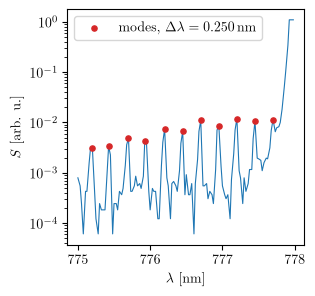

In [45]:
with plt.rc_context(SINGLE_COLUMN):
    fig, ax = plt.subplots()

    ax.plot(df_19mA["lambda_nm"], df_19mA["signal"], color="tab:blue", linewidth=0.8)
    ax.scatter(
        lambda_peaks,
        signal_peaks,
        color="tab:red",
        s=14,
        zorder=3,
        label=rf"modes, $\Delta\lambda = \qty{{{d_lambda_mean:.3f}}}{{\nano\meter}}$",
    )
    ax.set_yscale("log")
    ax.set_xlabel(r"$\lambda$ [\unit{\nano\meter}]")
    ax.set_ylabel(r"$S$ [arb. u.]")
    ax.legend()

    fig.savefig(export_dir / "mode_spectrum.pdf")
    plt.show()

### Result

|        | $\Delta\lambda$       | $n$ peaks | $L$ (placeholder) | $\bar{n}$       |
|--------|------------------------|-----------|--------------------|------------------|
| `19mA` | $(0.250 \pm 0.005)$ nm | 11        | 300 µm             | $4.02 \pm 0.08$  |

The 11 resolved modes are spaced with essentially no scatter (mean 0.250 nm, SEM 0.005 nm) -
a reproducible property of the cavity, not a fit artifact. The mode near 777.95 nm saturates
the lock-in and its plateau runs off the edge of the scan window, so it could not be located
precisely and is excluded from the fit.

$\bar{n}$ itself is **not final**: it scales as $1/L$, and `L_NM` in the cell above is a
placeholder (chosen only because it lands in the physically plausible range for AlGaAs, whose
bulk index is $\approx 3.6$). Once the real cavity length from the light-microscope
measurement is available, swap it into `L_NM` and every quantity downstream updates
automatically - no other cell needs to change.